# Estudo da dinâmica temporal do NFkB e espécies químicas relacionadas

**Artigo adotado como referência:** "Modeling heterogeneous signaling dynamics of macrophages reveals principles of information transmission in stimulus responses" (Guo, X., Adelaja, A., Singh, A. et al.) [1]

**Aluna:** Ana Luiza de Lima Silva <br>
**Docentes orientadores:** Dra. Juliana Helena Costa Smetana e Dr. Vinícius Francisco Wasques

## Introdução

  A ativação das vias de resposta do sistema imunológico contra patógenos invasores pode se iniciar a partir de diferentes estímulos extracelulares, ps quais vão desde o reconhecimento de padrões moleculares associados a patógenos (PAMPs), padrões moleculares associados a danos (DAMPs), a citocinas provenientes de respostas inflamatórias anteriores. No entanto, a efetividade dessa respota depende diretamente da capacidade das células de reconhcer, diferenciar e se ajustar cada tipo de invasor, convertendo essas informações em expressões gênicas úteis ao seu combate.
  
  O fator de transcrição nuclear NFkB atua enquanto regulador da resposta imune inata contra patógenos invasores. Em condições basais, ele permanece inativado no citoplasma, em associação à proteínas da família IkB. Ao ser ativado a partir de diferentes vias, ele migra para o núcleo celular, reconhecendo sequências específicas denominadas "kB sites" e iniciando a transcrição de diversos genes ao se ligar a esses sítios, como aqueles relacionados à resposta inflamatória, apoptose e diferenciação celular. Assim, ele permite que as células convertam esímulos extracelulares em diferentes respostas transcricionais.
  
  No artigo utilizado como referência [1], a via de ativação do NFkB é utilizada como mecanismo para avaliar a heterogeneidade célula-a-célula em populações geneticamente idênticas, realizando-se a escolha de cinco, dentre 52, espécies químicas para essa análise, sendo elas: a citocina TNF (Fator de Necrose Tumoral) e quatro PAMPs(Pam3CSK4, CpG, LPS e Poly(I:C)). A modelagem matemática proposta organiza-se em cinco módulos, contando com a inativação do NFkB no citoplasma devido à sua associação com a proteína IkBa e com o ciclo de feedback negativo NFkB-IkBa, por meio do qual o próprio NFkB ativa o gene IkBa, que codifica a proteína responsável por inativá-lo.
  
  Para tal abordagem, o artigo parte de um modelo mecanístico já determinado anteriormente por outros autores [2], os quais definem 52 equações diferenciais ordinárias (EDOs), 101 reações bioquímicas e 133 parâmetros cinéticas, descrevendo a dinâmica de sinalização, ativação e inativação do NFkB, e associando-o a ajustes estatísticos e métodos de aprendizado de máquina para reproduzir e avaliar a dinâmica de heterogeneidade entre uma população de células. <br>

## Objetivo deste notebook

Diferentemente da análise proposta pelo artigo adotado como referência [1], este notebook concentra-se em avaliar qualitativamente a dinâmica temporal da via de sinalização do NFkB. Para isso, implementa-se a modelagem matemática baseada em 52 EDOs apresentada, utilizando os parâmetros cinéticos presentes no material suplementar [1] e as condições iniciais obtidas ao determinar o estado estacionário do sistema. Ademais, empregou-se os Modelos de Crescimento Malthusiano e de Interação de Lotka-Voltera, resolvidos pelo Método de Euler, de modo a aproximar a avaliação de como diferentes estímulos afetam essa via de sinalização e se relacionam entre si.

## Metodologia

### Importando bibliotecas

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.integrate import solve_ivp
from scipy.integrate._ivp.bdf import BDF

from scipy.signal import find_peaks

### Definindo os estados iniciais, parâmetros utilizados e sistema de equações diferenciais empregado

As 52 espécies químicas, responsáveis por determinar o sistema de equações diferenciais ordinárias (EDOs) a ser avaliado, bem como os parâmetros cinéticos empregados, encontram-se descritos no material suplementar [1] presente noa artigo de referência. No entanto, as concentrações iniciais das espécies químicas não são apresentadas, sendo apenas descritas enquanto aquelas alcançadas no estado estacionário do sistema, de modo que sua implementação inicial corresponde a um vetor de 52 dimensões, composto apenas por zeros.

In [ ]:
# Vetor representativo dos estados iniciais das espécies químicas avaliadas
x0 = np.zeros(52)

In [ ]:
# Lista contendo os nomes das 52 espécies químicas avaliadas
nomes = ['LPS', 'CD14', 'CD14LPS', 'CD14LPSen', 'TLR4', 'TLR4en', 'TLR4LPS', 'TLR4LPSen', 'TNF', 'TNFR', 'TNFR_TNF', 'TTR', 'C1_off', 'C1', 'Pam3CSK', 'TLR2', 'CD14_P3CSK', 'TLR2_P3CSK', 'polyIC', 'polyIC_en', 'TLR3', 'TLR3_polyIC', 'CpG', 'CpG_en', 'TLR9', 'TLR9_CpG', 'TLR9_N', 'MyD88_off', 'MyD88', 'TRIF_off', 'TRIF', 'TRAF6_off', 'TRAF6', 'TAK1_off', 'TAK1', 'stim', 'IkBa', 'IkBan', 'IkBaNFkB', 'IkBaNFkBn', 'IkBat', 'IKKIkBaNFkB', 'IKKIkBa', 'NFkB', 'NFkBn', 'IKK_off', 'IKK', 'IKK_i', 'IkBat_cas1', 'IkBat_cas2', 'NFkBn_cas1', 'NFkBn_cas2']

In [ ]:
# Definindo o dicionário de parâmetros (psis) e os relacionando ao seu respectivo valor numérico

psi = {'psi_1.1': 1, 'psi_2.1': 2e-5, 'psi_3.1': 2, 'psi_4.1': 18, 'psi_5.1': 5.00E-07, 'psi_6.1': 6e-5, 'psi_6.2': 2.938, 'psi_6.3': 0.1775, 'psi_7.1': 0.3/12, 'psi_8.1': 30, 'psi_9.1': 0.0225, 'psi_9.2': 3.5, 'psi_10.1': 0.6, 'psi_10.2': 3.5, 'psi_11.1': 0.09/7, 'psi_11.2': 1/3.5, 'psi_12.1': 0.6/175, 'psi_12.2': 1/3.5, 'psi_13.1': 0, 'psi_13.2': 3.5, 'psi_14.1': 0.828, 'psi_14.2': 1/3.5, 'psi_15.1': 0.3/9, 'psi_16.1': 0.3/9, 'psi_17.1': 200, 'psi_18.1': 200, 'psi_19.1': 8e-3, 'psi_20.1': 8e-3, 'psi_21.1': 190, 'psi_22.1': 190, 'psi_23.1': 38, 'psi_24.1': 38, 'psi_25.1': 2, 'psi_26.1': 2, 'psi_27.1': 8.75, 'psi_27.2': 0.001, 'psi_28.1': 0.07, 'psi_28.2': 0.001, 'psi_29.1': 0.00112, 'psi_30.1': 8.78E-04, 'psi_31.1': 5.543, 'psi_32.1': 0.0277, 'psi_33.1': 5.543, 'psi_34.1': 0.0277, 'psi_35.1': 5.25E-05, 'psi_36.1': 0.065681, 'psi_37.1': 4.00E-02, 'psi_38.1': 0.028028, 'psi_39.1': 0.5, 'psi_40.1': 0.065681, 'psi_41.1': 0.04, 'psi_42.1': 0.07, 'psi_43.1': 0.0653, 'psi_44.1': 0.012, 'psi_45.1': 150, 'psi_45.2': 3, 'psi_45.3': 0.012448, 'psi_46.1': 2600, 'psi_47.1': 6, 'psi_48.1': 0.2, 'psi_49.1': 30, 'psi_50.1': 0.4, 'psi_51.1': 0.125, 'psi_52.1': 0.105, 'psi_52.2': 1, 'psi_53.1': 0.0116, 'psi_54.1': 8.224e-06, 'psi_55.1': 0.02384, 'psi_56.1': 1100, 'psi_56.2': 0.001, 'psi_57.1': 0.021, 'psi_57.2': 0.001, 'psi_58.1': 0.0125, 'psi_59.1': 34.08, 'psi_60.1': 0.03812, 'psi_61.1': 0.125, 'psi_62.1': 1.875, 'psi_63.1': 320.3, 'psi_64.1': 0.125, 'psi_65.1': 1889, 'psi_65.2': 1, 'psi_66.1': 0.5188, 'psi_67.1': 18.79, 'psi_67.2': 2, 'psi_67.3': 0.001116, 'psi_68.1': 1e-6, 'psi_69.1': 0.0004, 'psi_70.1': 1, 'psi_70.2': 0.001, 'psi_71.1': 1.8, 'psi_71.2': 0.001, 'psi_72.1': 5.543, 'psi_73.1': 0.07, 'psi_74.1': 0.02, 'psi_75.1': 0.004, 'psi_76.1': 150, 'psi_76.2': 3, 'psi_76.3': 0.0032, 'psi_77.1': 3e-6, 'psi_78.1': 0.0007, 'psi_79.1': 0.04, 'psi_79.2': 0.03, 'psi_79.3': 1, 'psi_79.4': 0.001, 'psi_80.1': 0.04, 'psi_80.2': 0.001, 'psi_81': 0.5, 'psi_82': 2.5e-2, 'psi_83.1': 0.0007, 'psi_84.1': 20, 'psi_85.1': 2e-6, 'psi_86.1': 4e-4, 'psi_87.1': 4e-4, 'psi_88.1': 0.015, 'psi_88.2': 0.5, 'psi_88.3': 1, 'psi_88.4': 0.001, 'psi_89.1': 0.028, 'psi_89.2': 0.001, 'psi_90.1': 3, 'psi_91.1': 0.5, 'psi_92.1': 3, 'psi_93.1': 1.60, 'psi_94.1': 200, 'psi_94.2': 3, 'psi_94.3': 0.0032, 'psi_95.1': 0, 'psi_96.1': 0.33, 'psi_97.1':0.33, 'psi_98.1': 0.0577623, 'psi_99.1':0.4, 'psi_100.1': 0.4, 'psi_101.1': 0.4}

In [ ]:
def sistema(t, x, psi):
    """ Implementa o sistema de 52 EDOs apresentado pelo artigo [1], o qual será utilizado como base para avaliar a variação temporal da concentração das espécies químicas na via de sinalização do NFkB.

    Args: 
        x: dicionário contendo as concentrações das 52 espécies químicas avaliadas
        psi: dicionário contendo os parâmetros considerados para a construção das EDOs

    Return:
        Vetor, proveniente da biblioteca "numpy", contendo as derivadas das 52 espécies químicas. A escolha desse formato se deu para possibilitar a posterior integração para determinar o estado estacionário do sistema, ou seja, o valor inicial atribuído a cada uma das espécies químicas.
    """

    # atribuindo o nome de cada parâmetro ao seu respectivo valor presente no dicionário "psi"
    psi11 = psi["psi_1.1"]
    psi21 = psi["psi_2.1"]
    psi31 = psi["psi_3.1"]
    psi41 = psi["psi_4.1"]
    psi51 = psi["psi_5.1"]
    psi61 = psi["psi_6.1"]
    psi62 = psi["psi_6.2"]
    psi63 = psi["psi_6.3"]
    psi71 = psi["psi_7.1"]
    psi81 = psi["psi_8.1"]
    psi91 = psi["psi_9.1"]
    psi92 = psi["psi_9.2"]
    psi101 = psi["psi_10.1"]
    psi102 = psi["psi_10.2"]
    psi111 = psi["psi_11.1"]
    psi112 = psi["psi_11.2"]
    psi121 = psi["psi_12.1"]
    psi122 = psi["psi_12.2"]
    psi131 = psi["psi_13.1"]
    psi132 = psi["psi_13.2"]
    psi141 = psi["psi_14.1"]
    psi142 = psi["psi_14.2"]
    psi151 = psi["psi_15.1"]
    psi161 = psi["psi_16.1"]
    psi171 = psi["psi_17.1"]
    psi181 = psi["psi_18.1"]
    psi191 = psi["psi_19.1"]
    psi201 = psi["psi_20.1"]
    psi211 = psi["psi_21.1"]
    psi221 = psi["psi_22.1"]
    psi231 = psi["psi_23.1"]
    psi241 = psi["psi_24.1"]
    psi251 = psi["psi_25.1"]
    psi261 = psi["psi_26.1"]
    psi271 = psi["psi_27.1"]
    psi272 = psi["psi_27.2"]
    psi281 = psi["psi_28.1"]
    psi282 = psi["psi_28.2"]
    psi291 = psi["psi_29.1"]
    psi301 = psi["psi_30.1"]
    psi311 = psi["psi_31.1"]
    psi321 = psi["psi_32.1"]
    psi331 = psi["psi_33.1"]
    psi341 = psi["psi_34.1"]
    psi351 = psi["psi_35.1"]
    psi361 = psi["psi_36.1"]
    psi371 = psi["psi_37.1"]
    psi381 = psi["psi_38.1"]
    psi391 = psi["psi_39.1"]
    psi401 = psi["psi_40.1"]
    psi411 = psi["psi_41.1"]
    psi421 = psi["psi_42.1"]
    psi431 = psi["psi_43.1"]
    psi441 = psi["psi_44.1"]
    psi451 = psi["psi_45.1"]
    psi452 = psi["psi_45.2"]
    psi453 = psi["psi_45.3"]
    psi461 = psi["psi_46.1"]
    psi471 = psi["psi_47.1"]
    psi481 = psi["psi_48.1"]
    psi491 = psi["psi_49.1"]
    psi501 = psi["psi_50.1"]
    psi511 = psi["psi_51.1"]
    psi521 = psi["psi_52.1"]
    psi522 = psi["psi_52.2"]
    psi531 = psi["psi_53.1"]
    psi541 = psi["psi_54.1"]
    psi551 = psi["psi_55.1"]
    psi561 = psi["psi_56.1"]
    psi562 = psi["psi_56.2"]
    psi571 = psi["psi_57.1"]
    psi572 = psi["psi_57.2"]
    psi581 = psi["psi_58.1"]
    psi591 = psi["psi_59.1"]
    psi601 = psi["psi_60.1"]
    psi611 = psi["psi_61.1"]
    psi621 = psi["psi_62.1"]
    psi631 = psi["psi_63.1"]
    psi641 = psi["psi_64.1"]
    psi651 = psi["psi_65.1"]
    psi652 = psi["psi_65.2"]
    psi661 = psi["psi_66.1"]
    psi671 = psi["psi_67.1"]
    psi672 = psi["psi_67.2"]
    psi673 = psi["psi_67.3"]
    psi681 = psi["psi_68.1"]
    psi691 = psi["psi_69.1"]
    psi701 = psi["psi_70.1"]
    psi702 = psi["psi_70.2"]
    psi711 = psi["psi_71.1"]
    psi712 = psi["psi_71.2"]
    psi721 = psi["psi_72.1"]
    psi731 = psi["psi_73.1"]
    psi741 = psi["psi_74.1"]
    psi751 = psi["psi_75.1"]
    psi761 = psi["psi_76.1"]
    psi762 = psi["psi_76.2"]
    psi763 = psi["psi_76.3"]
    psi771 = psi["psi_77.1"]
    psi781 = psi["psi_78.1"]
    psi791 = psi["psi_79.1"]
    psi792 = psi["psi_79.2"]
    psi793 = psi["psi_79.3"]
    psi794 = psi["psi_79.4"]
    psi801 = psi["psi_80.1"]
    psi802 = psi["psi_80.2"]
    psi811 = psi["psi_81"]
    psi821 = psi["psi_82"]
    psi831 = psi["psi_83.1"]
    psi841 = psi["psi_84.1"]
    psi851 = psi["psi_85.1"]
    psi861 = psi["psi_86.1"]
    psi871 = psi["psi_87.1"]
    psi881 = psi["psi_88.1"]
    psi882 = psi["psi_88.2"]
    psi883 = psi["psi_88.3"]
    psi884 = psi["psi_88.4"]
    psi891 = psi["psi_89.1"]
    psi892 = psi["psi_89.2"]
    psi901 = psi["psi_90.1"]
    psi911 = psi["psi_91.1"]
    psi921 = psi["psi_92.1"]
    psi931 = psi["psi_93.1"]
    psi941 = psi["psi_94.1"]
    psi942 = psi["psi_94.2"]
    psi943 = psi["psi_94.3"]
    psi951 = psi["psi_95.1"]
    psi961 = psi["psi_96.1"]
    psi971 = psi["psi_97.1"]
    psi981 = psi["psi_98.1"]
    psi991 = psi["psi_99.1"]
    psi1001 = psi["psi_100.1"]
    psi1011 = psi["psi_101.1"]

    # atribuindo o nome de cada espécie química à sua concentração no dicionário "x"
    LPS = x[0]
    CD14 = x[1]
    CD14LPS = x[2]
    CD14LPSen = x[3]
    TLR4 = x[4]
    TLR4en = x[5]
    TLR4LPS = x[6]
    TLR4LPSen = x[7]
    TNF = x[8]
    TNFR = x[9]
    TNFR_TNF = x[10]
    TTR = x[11]
    C1_off = x[12]
    C1 = x[13]
    Pam3CSK = x[14]
    TLR2 = x[15]
    CD14_P3CSK = x[16]
    TLR2_P3CSK = x[17]
    polyIC = x[18]
    polyIC_en = x[19]
    TLR3 = x[20]
    TLR3_polyIC = x[21]
    CpG = x[22]
    CpG_en = x[23]
    TLR9 = x[24]
    TLR9_CpG = x[25]
    TLR9_N = x[26]
    MyD88_off = x[27]
    MyD88 = x[28]
    TRIF_off = x[29]
    TRIF = x[30]
    TRAF6_off = x[31]
    TRAF6 = x[32]
    TAK1_off = x[33]
    TAK1 = x[34]
    stim = x[35]
    IkBa = x[36]
    IkBan = x[37]
    IkBaNFkB = x[38]
    IkBaNFkBn = x[39]
    IkBat = x[40]
    IKKIkBaNFkB = x[41]
    IKKIkBa = x[42]
    NFkB = x[43]
    NFkBn = x[44]
    IKK_off = x[45]
    IKK = x[46]
    IKK_i = x[47]
    IkBat_cas1 = x[48]
    IkBat_cas2 = x[49]
    NFkBn_cas1 = x[50]
    NFkBn_cas2 = x[51]

    # determinando as 52 EDOs, conforme apresentado pelo artigo [1]
    dLPS = (psi281*CD14LPS*psi282) - (psi271*CD14*psi272)*LPS
    dCD14 = (psi281*CD14LPS + psi291 + psi711*CD14_P3CSK) - (psi271*LPS + psi301 + psi701*Pam3CSK)*CD14
    dCD14LPS = (psi271*LPS*CD14 + psi321*TLR4LPS + psi371*CD14LPSen) - (psi281 + psi311*TLR4 + psi361)*CD14LPS
    dCD14LPSen = (psi341*TLR4LPSen + psi361*CD14LPS) - (psi331*TLR4en + psi371 + psi421)*CD14LPSen
    dTLR4 = (psi321*TLR4LPS + psi351 + psi391*TLR4en) - (psi311*CD14LPS + psi381)*TLR4
    dTLR4en = (psi341*TLR4LPSen + psi381*TLR4) - (psi331*CD14LPSen + psi391 + psi431)*TLR4en
    dTLR4LPS = (psi311*CD14LPS*TLR4 + psi411*TLR4LPSen) - (psi321 + psi401)*TLR4LPS
    dTLR4LPSen = (psi331*CD14LPSen*TLR4en + psi401*TLR4LPS) - (psi341 + psi411 + psi441)*TLR4LPSen
    dTNF = (psi571*TNFR_TNF*psi572) - (psi531 + psi561*TNFR*psi562)*TNF
    dTNFR = (psi541 + psi571*TNFR_TNF) - (psi551 + psi561*TNF)*TNFR
    dTNFR_TNF = (psi561*TNF*TNFR + psi601*C1_off) - (psi571 + psi581 + psi591*TTR)*TNFR_TNF
    dTTR = (psi601*C1_off) - (psi591*TNFR_TNF)*TTR
    dC1_off = (psi591*TNFR_TNF*TTR + psi631*C1) - (psi601 + psi611 + psi621)*C1_off
    dC1 = (psi621*C1_off) - (psi631 + psi641)*C1
    dPam3CSK = (psi711*CD14_P3CSK*psi712) - (psi701*CD14*psi702)*Pam3CSK
    dTLR2 = (psi681 + psi741*TLR2_P3CSK) - (psi691 + psi721*CD14_P3CSK)*TLR2
    dCD14_P3CSK = (psi701*Pam3CSK*CD14 + psi741*TLR2_P3CSK) - (psi711 + psi721*TLR2 + psi731)*CD14_P3CSK
    dTLR2_P3CSK = (psi721*CD14_P3CSK*TLR2) - (psi741 + psi751)*TLR2_P3CSK
    dpolyIC = (psi801*polyIC_en*psi802) - (psi791/((polyIC**psi793 + psi792**psi793))*psi794)*(polyIC**psi793)
    dpolyIC_en = (((psi791*(polyIC**psi793))/((polyIC**psi793) + (psi792**psi793))) + psi821*TLR3_polyIC) - (psi801 + psi811*TLR3)*polyIC_en
    dTLR3 = (psi771 + psi821*TLR3_polyIC) - (psi781 + psi811*polyIC_en)*TLR3
    dTLR3_polyIC = (psi811*polyIC_en*TLR3) - (psi821 + psi831)*TLR3_polyIC
    dCpG = (psi891*CpG_en*psi892) - (psi881*psi884/((CpG**psi883) + (psi882**psi883)))*(CpG**psi883)
    dCpG_en = (((psi881*(CpG**psi883))/((CpG**psi883)+(psi882**psi883))) + psi911*TLR9_CpG) - (psi891 + psi901*TLR9)*CpG_en
    dTLR9 = (psi851 + psi911*TLR9_CpG) - (psi861 + psi901*CpG_en)*TLR9
    dTLR9_CpG = (psi901*CpG_en*TLR9) - (psi911 + psi921*TLR9_N + psi931)*TLR9_CpG
    dTLR9_N = (psi851) - (psi871 + psi921*TLR9_CpG)*TLR9_N
    dMyD88_off = (psi461*MyD88) - (((psi451*(TLR4LPS**psi452))/((TLR4LPS**psi452)+(psi453**psi452))) + ((psi761*(TLR2_P3CSK**psi762))/((TLR2_P3CSK**psi762) + (psi763**psi762))) + ((psi941*(TLR9_CpG**psi942))/((TLR9_CpG**psi942) + (psi943**psi942))))*MyD88_off
    dMyD88 = (((psi451*(TLR4LPS**psi452))/(((TLR4LPS**psi452) + (psi453**psi452))))*MyD88_off + ((psi761*(TLR2_P3CSK**psi762))/(((TLR2_P3CSK**psi762) + (psi763**psi762))))*MyD88_off + ((psi941*(TLR9_CpG**psi942))/(((TLR9_CpG**psi942) + (psi943**psi942))))*MyD88_off) - (psi461)*MyD88
    dTRIF_off = (psi481*TRIF) - (psi471*TLR4LPSen + psi841*TLR3_polyIC)*TRIF_off
    dTRIF = (psi471*TRIF_off*TLR4LPSen + psi841*TRIF_off*TLR3_polyIC) - (psi481)*TRIF
    dTRAF6_off = (psi511*TRAF6) - (psi491*MyD88 + psi501*TRIF)*TRAF6_off
    dTRAF6 = (psi491*MyD88*TRAF6_off + psi501*TRIF*TRAF6_off) - (psi511)*TRAF6
    dTAK1_off = (psi661*TAK1) - (psi521*TRAF6*psi522 + psi651*C1*psi522)*TAK1_off
    dTAK1 = (psi521*TRAF6*TAK1_off*psi522 + psi651*C1*TAK1_off*psi522) - (psi661)*TAK1
    dstim = 0
    dIkBa = (psi81*IkBat_cas2 + psi111*IkBan*psi112 + psi191*IkBaNFkB + psi241*IKKIkBa) - (psi91 + psi151 + psi171*NFkB + psi221*IKK)*IkBa
    dIkBan = (psi91*IkBa*psi92 + psi201*IkBaNFkBn) - (psi111 + psi161 + psi181*NFkBn)*IkBan
    dIkBaNFkB = (psi141*IkBaNFkBn*psi142 + psi171*IkBa*NFkB + psi231*IKKIkBaNFkB) - (psi131 + psi191 + psi211*IKK)*IkBaNFkB
    dIkBaNFkBn = (psi131*IkBaNFkB*psi132 + psi181*IkBan*NFkBn) - (psi141 + psi201)*IkBaNFkBn
    dIkBat = (psi51 + ((psi61*(NFkBn_cas2**psi62))/((NFkBn_cas2**psi62)+(psi63**psi62)))) - (psi961)*IkBat
    dIKKIkBaNFkB = (psi211*IKK*IkBaNFkB) - (psi231 + psi251)*IKKIkBaNFkB
    dIKKIkBa = (psi221*IKK*IkBa) - (psi241 + psi261)*IKKIkBa
    dNFkB = (psi121*NFkBn*psi122 + psi191*IkBaNFkB + psi251*IKKIkBaNFkB) - (psi101 + psi171*IkBa + psi951)*NFkB
    dNFkBn = (psi101*NFkB*psi102 + psi201*IkBaNFkBn) - (psi121 + psi181*IkBan)*NFkBn
    dIKK_off = (psi41*IKK_i) - (psi11*stim + psi21 + ((psi671*(TAK1**psi672))/((TAK1**psi672) + (psi673**psi672))))*IKK_off
    dIKK = (psi11*stim*IKK_off + psi21*IKK_off + psi231*IKKIkBaNFkB + psi241*IKKIkBa + psi251*IKKIkBaNFkB + psi261*IKKIkBa + ((psi671*(TAK1**psi672)*IKK_off)/((TAK1**psi672) + (psi673**psi672)))) - (psi31 + psi211*IkBaNFkB + psi221*IkBa)*IKK
    dIKK_i = (psi31*IKK) - (psi41)*IKK_i
    dIkBat_cas1 = (psi961*IkBat) - (psi971)*IkBat_cas1
    dIkBat_cas2 = (psi971*IkBat_cas1) - (psi981)*IkBat_cas2
    dNFkBn_cas1 = (psi991*NFkBn) - (psi1001)*NFkBn_cas1
    dNFkBn_cas2 = (psi1001*NFkBn_cas1) - (psi1011)*NFkBn_cas2

    return np.array([dLPS, dCD14, dCD14LPS, dCD14LPSen, dTLR4, dTLR4en, dTLR4LPS, dTLR4LPSen, dTNF, dTNFR, dTNFR_TNF, dTTR, dC1_off, dC1, dPam3CSK, dTLR2, dCD14_P3CSK, dTLR2_P3CSK, dpolyIC, dpolyIC_en, dTLR3, dTLR3_polyIC, dCpG, dCpG_en, dTLR9, dTLR9_CpG, dTLR9_N, dMyD88_off, dMyD88, dTRIF_off, dTRIF, dTRAF6_off, dTRAF6, dTAK1_off, dTAK1, dstim, dIkBa, dIkBan, dIkBaNFkB, dIkBaNFkBn, dIkBat, dIKKIkBaNFkB, dIKKIkBa, dNFkB, dNFkBn, dIKK_off, dIKK, dIKK_i, dIkBat_cas1, dIkBat_cas2, dNFkBn_cas1, dNFkBn_cas2])

### Integração do sistema até que o estado estacionário seja atingido

Uma vez que as concentrações iniciais das espécies químicas apresentadas não são fornecidas, com base na metodologia de determinação do estado estacionário empregada pelo artigo, optou-se pela adoção do método BDF (Fórmula de Diferenciação Reversa). O BDF se trata de um método linear implícito de múltiplos passos que aproxima a derivada de uma função utilizando pontos no tempo já calculados, ou seja, se trata de um método iterativo que calcula um sistema não linear a cada passo de sua execução. O uso desse método se encaixa ao sistema de EDOs apresentado pois se trata de um problema de valor inicial e sistema rígido, apresentando tanto reações muito rápidas quanto muito lentas.

In [ ]:
# definindo o intervalo temporal (1 hora), dividido em 6001 pontos igualmente espaçados
ti = 0
tf = 60
tempo = np.linspace(ti, tf, 6001)

# resolvendo o sistema de EDOs através do método BDF
solucao_integral = solve_ivp(
    sistema,
    (ti, tf),
    x0,                                
    method="BDF",       
    args=(psi,),
    t_eval=tempo,
    rtol=1e-8,
    atol=1e-10
)

# armazenando o último ponto obtido com a integração, ou seja, o estado estacionário procurado
x_ss = solucao_integral.y[:, -1]

'''obtendo a derivada em relação ao último ponto da integração (se próxima de zero, então o estado estacionário foi atingido)'''
dx_ss = sistema(solucao_integral.t[-1], x_ss, psi) 

print("max |dx/dt| no estado final:", np.max(np.abs(dx_ss)))


max |dx/dt| no estado final: 0.001062525567848676


### Aplicação do método de Euler para resolução numérica do sistema proposto

O método de Euler empregado nessa seção consiste em um método explícito de integração numérica, aproximando a solução de um problema de valor inicial de modo que $y_{n+1} = y_n + hf(t_n, y_n)$, onde h é o passo temporal determinado entre os instantes a serem calculados e $f(t_n, y_n)$ é a derivada calculada no instante atual. Para o sistema apresentado, optou-se pela escolha de um passo pequeno, com h = 0,001, para o qual observou-se menores divergências e oscilações.

In [ ]:
def euler(f, x, tempo, psi):
    """Define a aplicação do Método de Euler a um sistema de equações.
    
    Args:
        f: equação a ser avaliada
        x: valor inicial atribuído à equação
        tempo: intervalo temporal a ser avaliado
        psi: parâmetros presentes na equação

    Return:
        Lista com a estrutura de listas internas (representativo de uma matriz), em que cada lista interna representa o valor obtido para a equação em um dos intervalos de tempo determinados.
    """

    # defindo o formato da matriz de retorno
    X = np.zeros((len(tempo), len(x)))

    # atribuindo a primeira linha da matriz como o estado inicial da equação fornecida
    X[0] = x

    # avaliando a evolução temporal da equação conforme o passo "h" e seu estado anterior
    for i in range(len(tempo)-1):
        
        h = tempo[i+1] - tempo[i]

        X[i+1] = X[i] + h*f(tempo[i], X[i], psi)

    return X

### Comparação entre os métodos BDF e Euler ao aproximar a solução do sistema

Realiza-se a comparação entre os métodos BDF e Euler, com ambos partindo do estado estacionário já determinado. Com isso, busca-se avaliar o erro absoluto entre esses métodos, além de produzir gráficos que permitem a visualização da dinâmica temporal das concentrações de cada espécie química.

In [ ]:
# gerando um DataFrame para verificar os maiores valores de erro encontrados ao comparar os dos métodos, ambos partindo do estado estacionário
solucao_integral_ss = solve_ivp(
    sistema, 
    (ti, tf), 
    x_ss, 
    method="BDF", 
    args=(psi,),
    t_eval=tempo, 
    rtol=1e-8, 
    atol=1e-10
)

solucao_euler_ss = euler(sistema, x_ss, tempo, psi)

erro_abs_ss = np.abs(solucao_euler_ss.T - solucao_integral_ss.y) 

erro_relativo_ss = np.divide(
    erro_abs_ss.max(axis=1),
    np.where(x_ss == 0, np.nan, x_ss)
) * 100

tabela_especies_ss = pd.DataFrame({
    "Espécie": nomes,
    "Valor no estado estacionário": x_ss,
    "Valor final (Euler)": solucao_euler_ss[-1],
    "Valor final (BDF)": solucao_integral_ss.y[:, -1],
    "Erro abs. máximo": erro_abs_ss.max(axis=1),
    "Erro abs. médio": erro_abs_ss.mean(axis=1),
    "Erro relativo máx. (%)": erro_relativo_ss,
}).sort_values("Erro abs. máximo", ascending=False).reset_index(drop=True)

print("10 espécies com maior erro absoluto:")
tabela_especies_ss.head(10)

10 espécies com maior erro absoluto:


,Espécie,Valor no estado estacionário,Valor final (Euler),Valor final (BDF),Erro abs. máximo,Erro abs. médio,Erro relativo máx. (%)
0,CD14,0.065461,0.127562,0.127562,2.659641e-07,1.355824e-07,0.000406
1,IkBan,0.004427,0.008093,0.008093,2.417345e-07,1.761919e-07,0.005460
2,IkBa,0.003929,0.005076,0.005076,8.487765e-08,6.780763e-08,0.002160
3,TLR4,0.002756,0.005041,0.005041,3.228997e-08,1.722530e-08,0.001172
4,TNFR,0.000262,0.000325,0.000325,3.629753e-09,2.892460e-09,0.001383
5,TLR4en,0.000133,0.000247,0.000247,1.609791e-09,8.587538e-10,0.001211
6,TLR3,0.000176,0.000345,0.000345,5.802385e-10,2.947316e-10,0.000329
7,TLR9,0.000119,0.000234,0.000234,2.291460e-10,1.156937e-10,0.000193
8,TLR9_N,0.000119,0.000234,0.000234,2.291460e-10,1.156937e-10,0.000193
9,TLR2,0.000059,0.000117,0.000117,1.145730e-10,5.784683e-11,0.000193


In [ ]:
tabela_valores = pd.DataFrame({
    "Espécie": nomes,
    "Valor final - Euler": solucao_euler_ss[-1],   
    "Valor final - BDF": solucao_integral_ss.y[:, -1],     
})

tabela_valores.reset_index(drop=True)

,Espécie,Valor final - Euler,Valor final - BDF
0,LPS,0.000000,0.000000
1,CD14,0.127562,0.127562
2,CD14LPS,0.000000,0.000000
3,CD14LPSen,0.000000,0.000000
4,TLR4,0.005041,0.005041
5,TLR4en,0.000247,0.000247
6,TLR4LPS,0.000000,0.000000
7,TLR4LPSen,0.000000,0.000000
8,TNF,0.000000,0.000000
9,TNFR,0.000325,0.000325


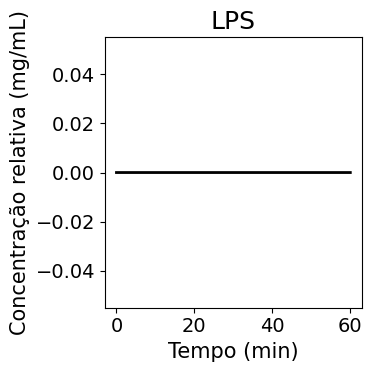

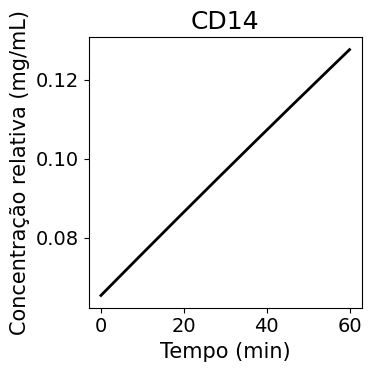

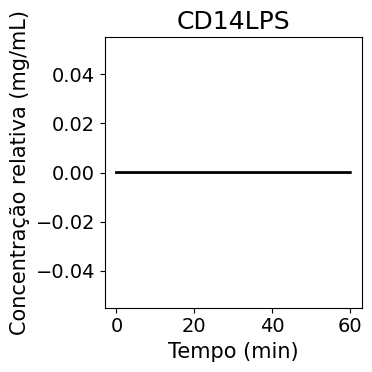

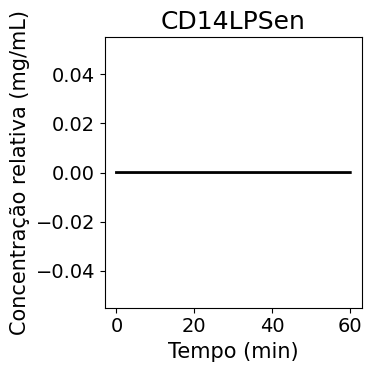

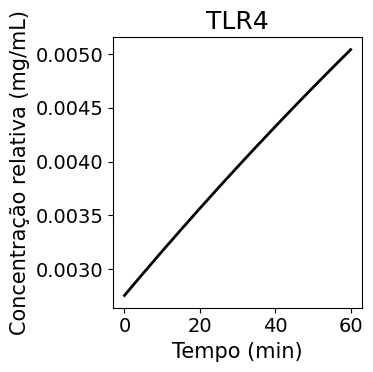

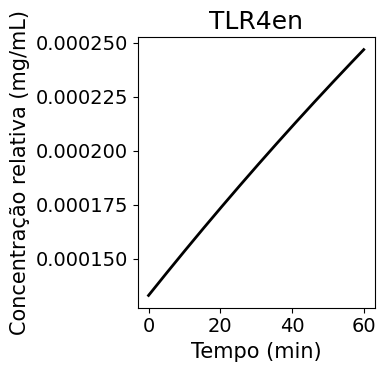

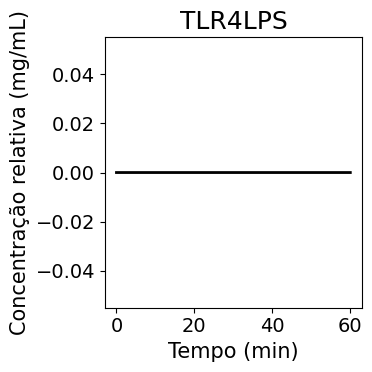

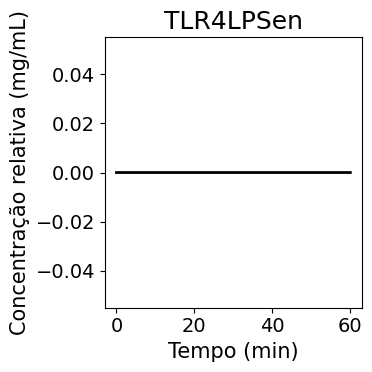

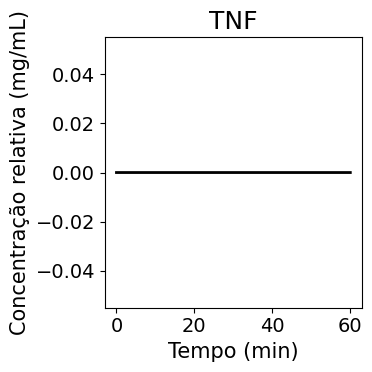

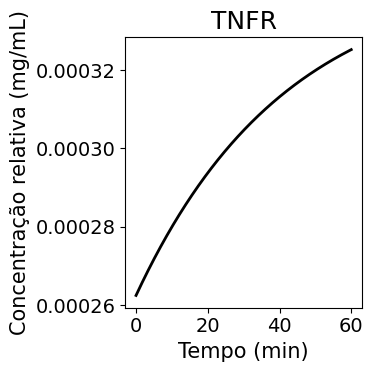

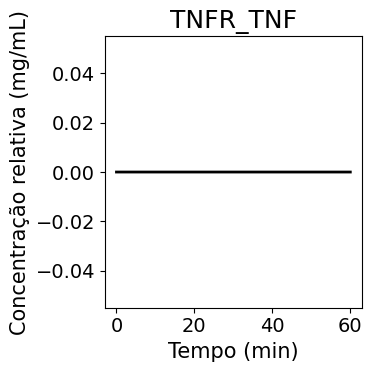

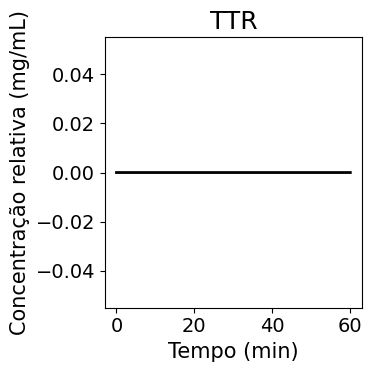

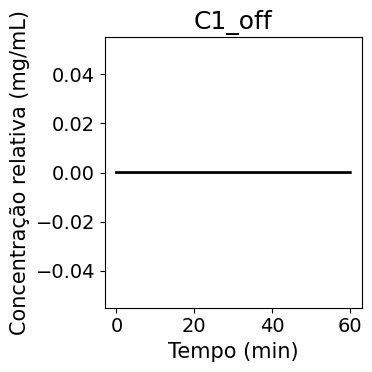

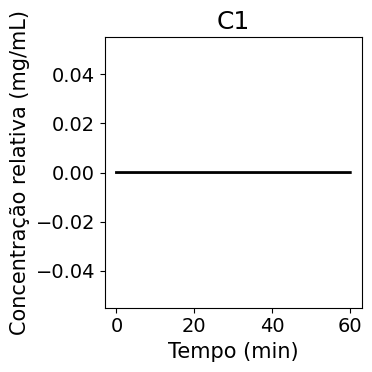

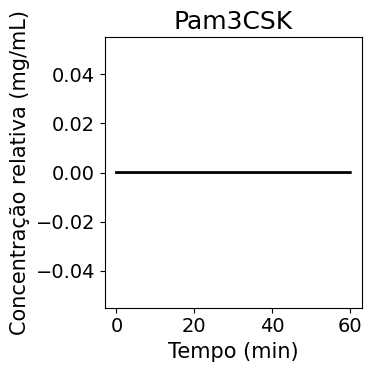

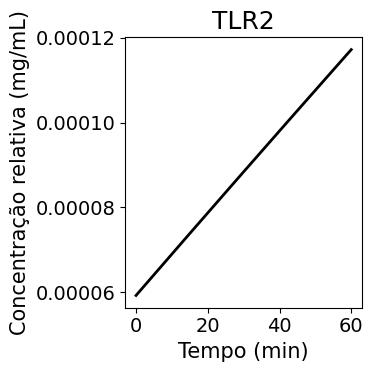

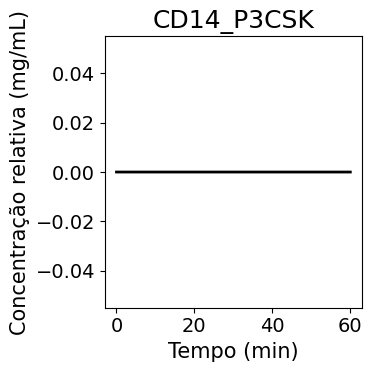

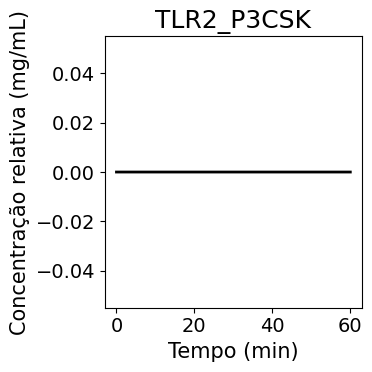

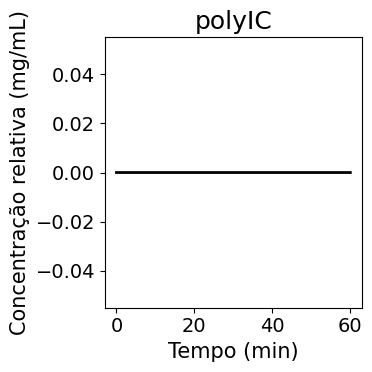

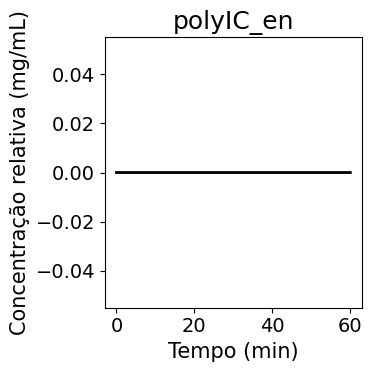

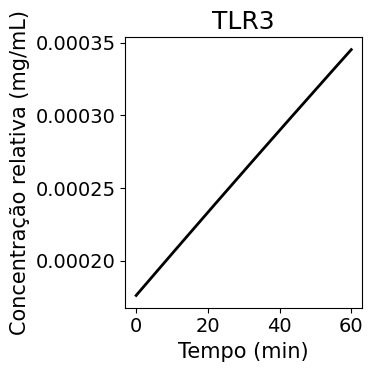

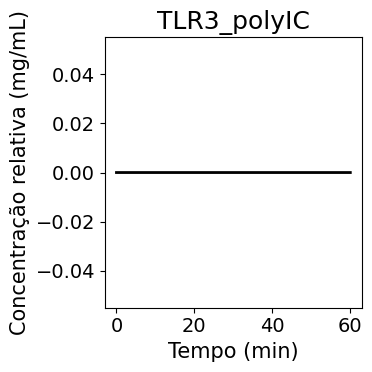

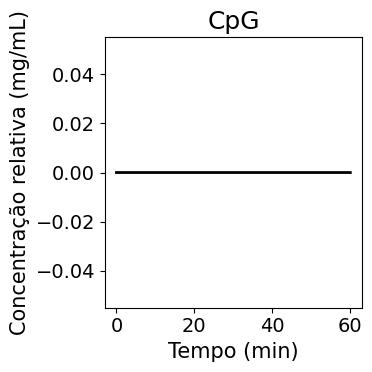

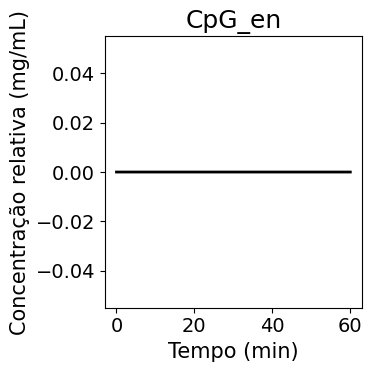

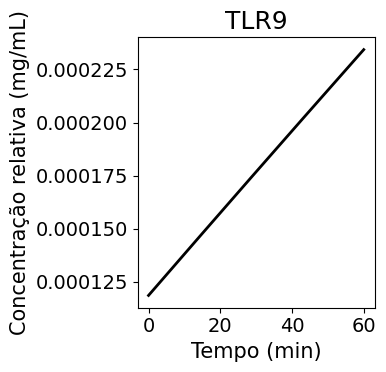

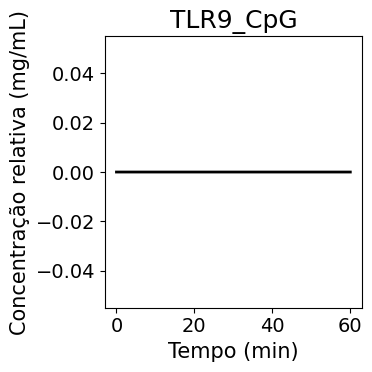

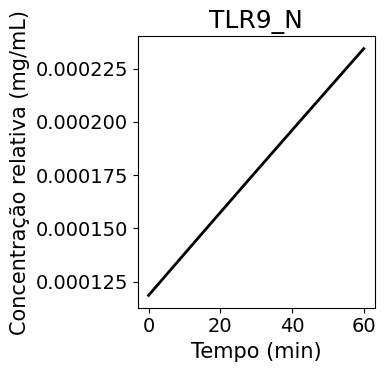

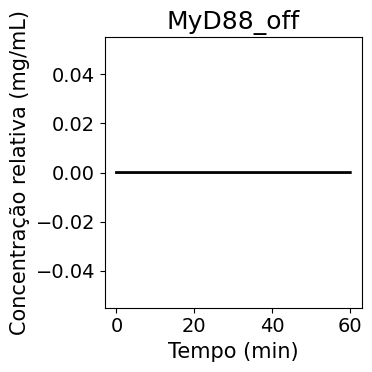

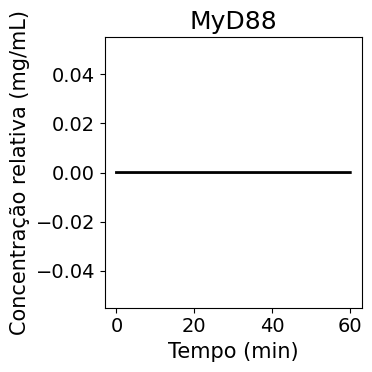

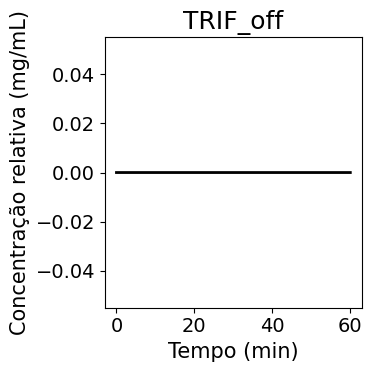

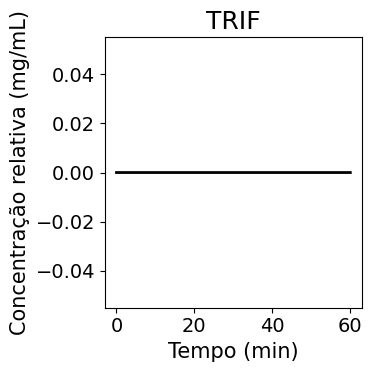

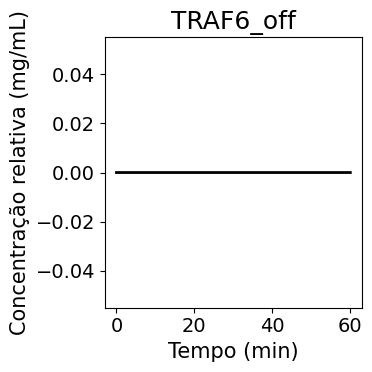

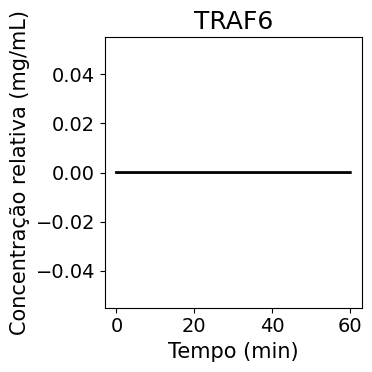

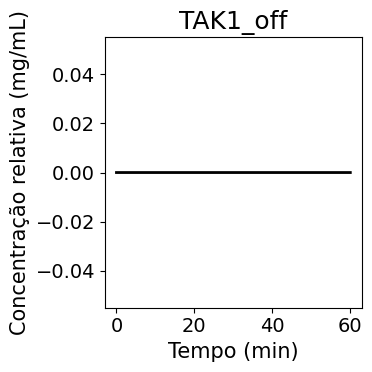

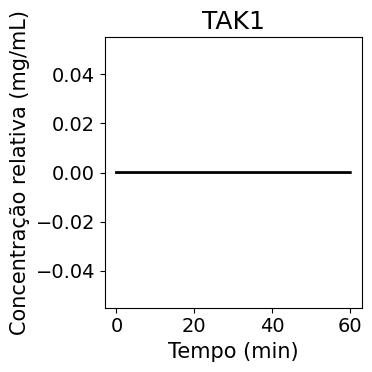

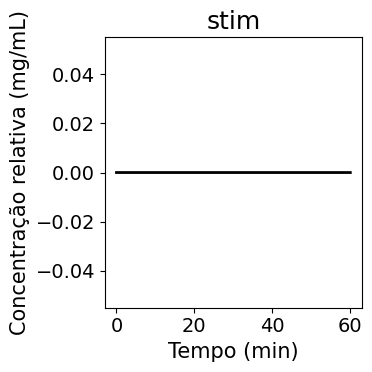

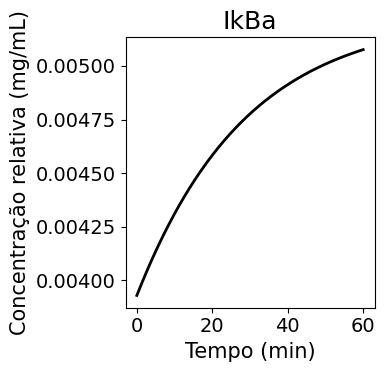

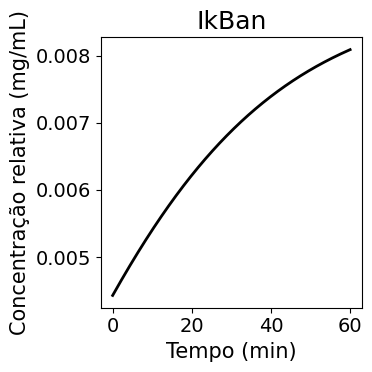

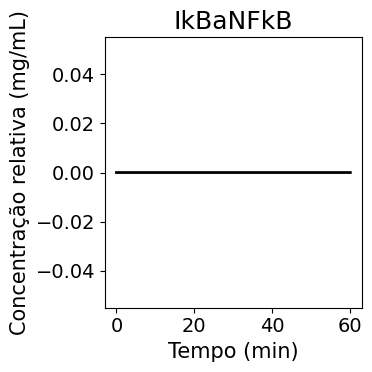

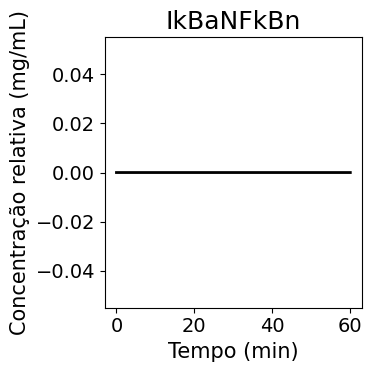

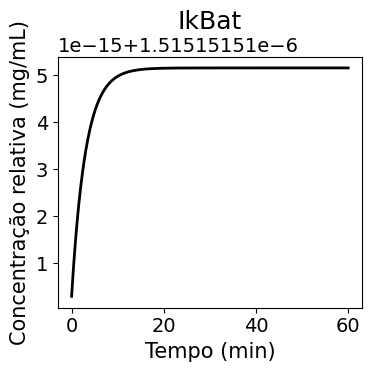

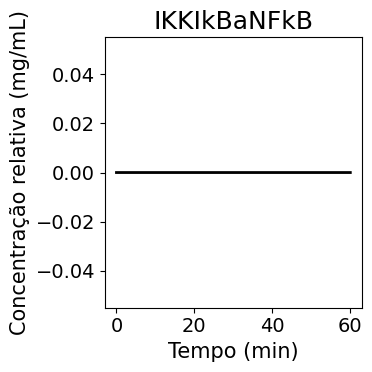

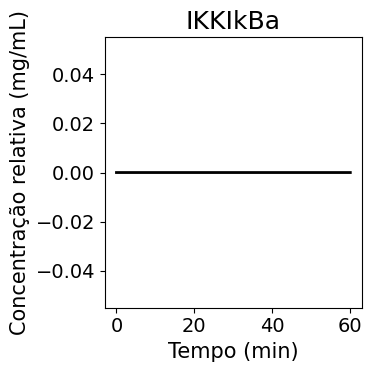

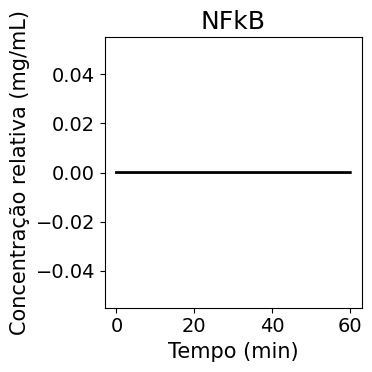

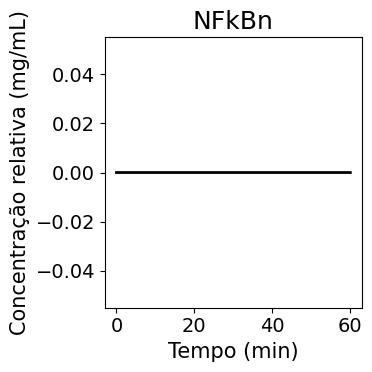

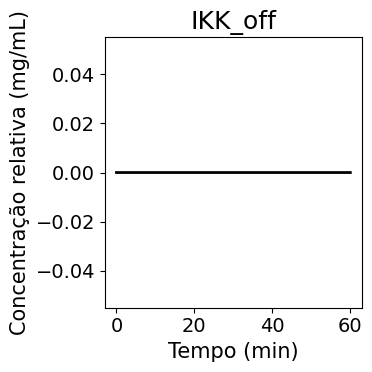

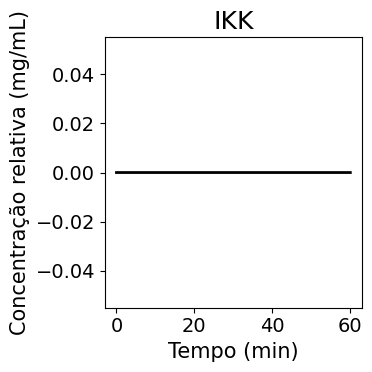

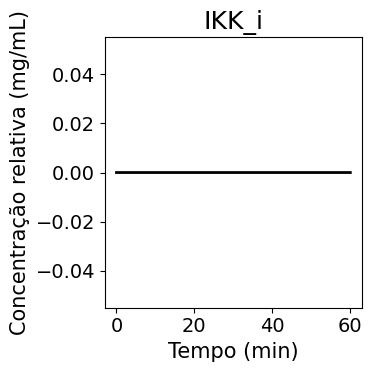

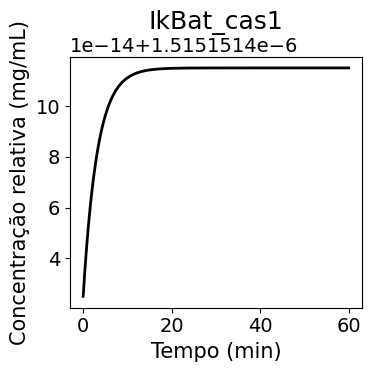

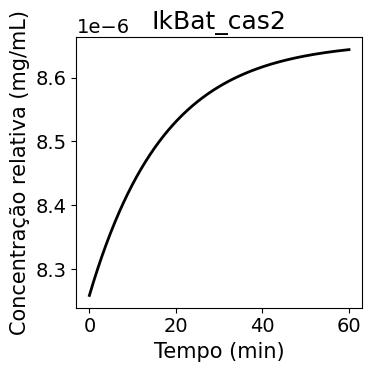

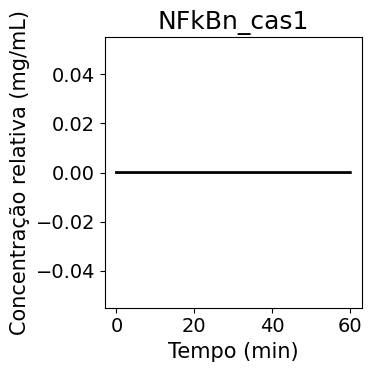

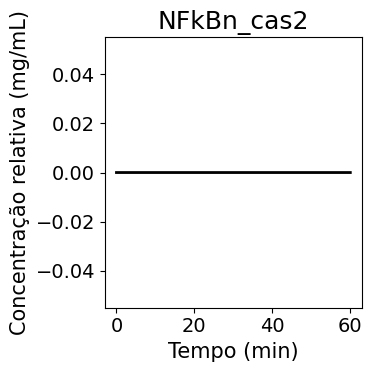

In [ ]:
import matplotlib.pyplot as plt
import os

os.makedirs("figuras_artigo", exist_ok=True)

plt.rcParams.update({
    'font.size': 16,          # tamanho base (afeta o que não for sobrescrito abaixo)
    'axes.titlesize': 18,     # título do gráfico (ex. "CD14")
    'axes.labelsize': 15,     # rótulos dos eixos ("Tempo (min)", "Concentração...")
    'xtick.labelsize': 14,    # números do eixo x
    'ytick.labelsize': 14,    # números do eixo y
    'legend.fontsize': 14,
    'lines.linewidth': 2,     # bônus: linha mais grossa também ajuda a legibilidade quando reduzida
})
for i in range(52):
    fig, ax = plt.subplots(figsize=(4, 4))

    ax.plot(tempo, solucao_euler_ss[:, i], color="black")

    ax.set_title(nomes[i])
    ax.set_xlabel("Tempo (min)")
    ax.set_ylabel("Concentração relativa (mg/mL)")

    fig.tight_layout()

    nome_arquivo = f"{i+1:02d}_{nomes[i].replace(' ', '_').replace('/', '-')}"
    fig.savefig(f"figuras_artigo/{nome_arquivo}.png", format="png", dpi=300, bbox_inches="tight")

    plt.show()
    plt.close(fig)

In [ ]:
# determinando as dimensões da figura para acomodar 52 gráficos
fig, axs = plt.subplots(13, 4, figsize=(18, 32), sharex=True)

axs = axs.flatten()

for i in range(52):

    # gráfico gerado pela resolução através do método de Euler
    axs[i].plot(tempo, solucao_euler_ss[:, i], label="Euler")

    # gráfico gerado pela resolução através do método BDF
    axs[i].plot(solucao_integral_ss.t, solucao_integral_ss.y[i], "--", label="BDF")

    axs[i].set_title(nomes[i])
    axs[i].set_ylabel("Concentração relativa (mg/mL)")
    axs[i].set_xlabel("Tempo (min)")
    axs[i].grid(True)
    axs[i].legend(fontsize=7)

plt.suptitle(
    "Comparação entre os métodos de Euler e BDF",
    fontsize=16,
    y=1.002
)
plt.tight_layout()
plt.savefig("Dinâmica temporal", dpi=300,bbox_inches='tight')

plt.show()

: 

### Modelo de crescimento malthusiano

O modelo de crescimento malthusiano propõe que a a variação de uma população é proporcional à população em cada instante, ou seja, da forma $P_n - P_{n-1} = αP_{n-1}$. No sistema de EDOs apresentado, a aplicação desse modelo adota o formato $\frac{dx}{dt} = p_i - c_i x$  , sendo $p_i$ a taxa de produção constante e $c_i$ a taxa de degradação associada a essa equação.

Para obter a solução desse modelo, utilizou-se duas estratégias. A primeira delas consiste na solução analítica exata do sistema, sob a forma $$x(t) = \frac{p_i}{c_i} + \left(x_0 - \frac{p_i}{c_i}\right) e^{-c_i t}$$, enquanto a segunda adota o método de Euler, já apresentado anteriormente, para o qual $y_n+1 = y_n + hf(t_n, y_n)$.

In [ ]:
# Taxa de produção adotada pelo modelo malthusiano
p_i = 8.22E-03     

# Taxa de degradação adotada pelo modelo malthusiano
c_i = 2.32E-02      

# condição inicial adotada pelo modelo malthusiano
x0_malthus = 2.62E-04 

# intervalo temporal avaliado
tempo_malthus = np.linspace(0, 40, 401)

In [ ]:
def malthus_analitico(t, p_i, c_i, x0):
    """Determina a solução analítica do modelo malthusiano"""
    
    return p_i/c_i + (x0 - p_i/c_i) * np.exp(-c_i*t)

resultado_analitico = malthus_analitico(tempo_malthus, p_i, c_i, x0_malthus)

In [ ]:
def euler_malthus(tempo, x0, I, k):
    """Aplica o método de Euler ao modelo malthusiano determinado."""
    
    h = tempo[1] - tempo[0]

    x = np.zeros(len(tempo))
    x[0] = x0

    for i in range(len(tempo)-1):
        x[i+1] = x[i] + h*(I - k*x[i])

    return x

resultado_euler_malthus = euler_malthus(tempo_malthus, x0_malthus, p_i, c_i) 

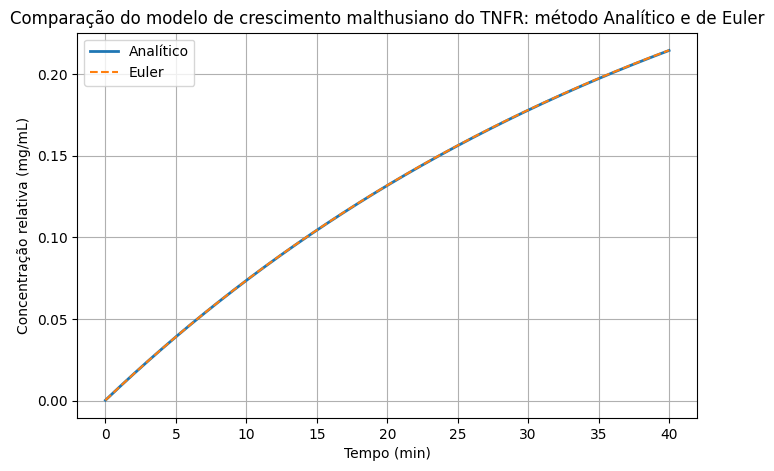

Erro máximo entre Euler e Analítico: 0.00015082784218306555


In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(tempo_malthus, resultado_analitico, label="Analítico", linewidth=2)

plt.plot(tempo_malthus, resultado_euler_malthus, "--", label="Euler")

plt.xlabel("Tempo (min)")
plt.ylabel("Concentração relativa (mg/mL)")
plt.title("Comparação do modelo de crescimento malthusiano do TNFR: método Analítico e de Euler")
plt.legend()
plt.grid()
plt.savefig("Modelo Malthusiano", dpi=300,bbox_inches='tight')
plt.show()

print("Erro máximo entre Euler e Analítico:", np.max(np.abs(resultado_euler_malthus - resultado_analitico)))

#### Tabela de comparação e avaliação do erro

In [ ]:
# escolha de nove pontos igualmente espaçados dentro do intervalo de tempo definido
pontos = np.linspace(0, len(tempo_malthus)-1, 9).astype(int)

tabela_malthus_pontos = pd.DataFrame({
    "Tempo": tempo_malthus[pontos],
    "Resultado analítico": resultado_analitico[pontos],
    "Resultado Euler": resultado_euler_malthus[pontos],
    "Erro absoluto": np.abs(resultado_euler_malthus[pontos] - resultado_analitico[pontos]),
})
tabela_malthus_pontos

,Tempo,Resultado analítico,Resultado Euler,Erro absoluto
0,0.0,0.000262,0.000262,1.555830e-17
1,5.0,0.039039,0.039082,4.248577e-05
2,10.0,0.073569,0.073645,7.565995e-05
3,15.0,0.104317,0.104418,1.010532e-04
4,20.0,0.131698,0.131818,1.199724e-04
5,25.0,0.156079,0.156213,1.335315e-04
6,30.0,0.177790,0.177933,1.426782e-04
7,35.0,0.197124,0.197272,1.482166e-04
8,40.0,0.214340,0.214490,1.508278e-04


### Modelo de interação Lotka-Volterra

O modelo de interação presa-predador de Lotka-Voltera é formado por um sistema de equações diferenciais ordinárias não-lineares que descreve a interação entre duas populações. Ele pode ser descrito por 
$$
\frac{dx}{dt}=\alpha x-\beta xy
$$

$$
\frac{dy}{dt}= -\gamma y + \delta xy,
$$

em que:

- $x(t)$ representa a primeira população (presa);
- $y(t)$ representa a segunda população (predador);
- $\alpha$ corresponde à taxa de crescimento da presa;
- $\beta$ representa a intensidade da interação entre as espécies;
- $\gamma$ corresponde à taxa de mortalidade do predador;
- $\delta$ representa a eficiência com que a interação promove o crescimento do predador.

Após sua implementação, o modelo é resolvido numericamente pelo método de Euler, sendo posteriormente gerados gráficos que permitem avaliar separadamente a dinâmica temporal de cada uma das espécies, além do gráfico de plano de fases, o qual permite visualizar a interação entre as espécies avaliadas.

Para aplicar esse modelo à dinâmica do NFkB, adotou-se a analogia presa-predador entre o NFkB nuclear (NFkBn), o qual atua como "presa", pois sua atividade transcricional impulsiona a produção do seu próprio inibidor, e a proteína IkBa, que atua como "predador", uma vez que sua acumulação leva à inativação e à exportação do NFkB do núcleo, fechando o ciclo de retroalimentação negativa. Essa relação mútua (NFkB ativa a transcrição de IkBa; IkBa, por sua vez, inibe e remove o NFkB do núcleo) é estruturalmente análoga à interação presa-predador, compondo um padrão oscilatório com período reportado entre aproximadamente 90 e 110 minutos.

Os parâmetros foram definidos com base na ordem de grandeza das taxas de produção e degradação dessas espécies químicas, já presentes no modelo mecanístico de 52 EDOs e no período de oscilação esperado para o par NFkB-IkBa, resultando em $\alpha=0{,}05$, $\beta=0{,}125$, $\delta=0{,}267$ e $\gamma=0{,}08$ (todos em min$^{-1}$, exceto $\beta$ e $\delta$, que carregam a unidade inversa de concentração). As condições iniciais (0,5 para a presa e 0,2 para o predador) foram escolhidas afastadas do ponto de equilíbrio, de modo que a órbita gerada tenha amplitude visível nos gráficos, sem deixar de ser uma trajetória fechada e limitada.

In [ ]:
def lotka_voltera(t, x, p):
    """Implementa o modelo de interação presa-predador de Lotka-Voltera.
    
    Args:
        t: tempo pelo qual o modelo será interpretado
        x: lista contendo as espécies que representam a presa e predador, respectivamente
        p: dicionário de parâmetros

    Return:
        Vetor contendo a taxa de crescimento da presa subtraída da taxa de predação e a taxa de crescimento do predador em função da presa disponível subtraída da mortalidade natural
    """

    presa, predador = x

    dpresa = (p["alpha"]*presa - p["beta"]*presa*predador)

    dpredador = (p["delta"]*presa*predador - p["gamma"]*predador)

    return np.array([dpresa, dpredador])

In [ ]:
# Parâmetros e condições iniciais
parametros = {"alpha": 0.05, "beta": 0.125, "delta": 0.267, "gamma": 0.08}
presa_i, predador_i = 0.5, 0.2

tempo_lv = np.linspace(0, 300, 30001)
h = tempo_lv[1] - tempo_lv[0]

#### Método de Euler para avaliar a dinâmica temporal do modelo Lotka-Voltera

In [ ]:
# criando o vetor para retorno da dinâmica temporal
XY = np.zeros((len(tempo_lv), 2))

# definindo os estados iniciais da presa e predador
XY[0] = [presa_i, predador_i]

# implementando o método de euler
for i in range(len(tempo_lv)-1):

    XY[i+1] = (XY[i] + h*lotka_voltera(tempo_lv[i], XY[i], parametros))

#### Comparando a dinâmica temporal das populações de presa e predador

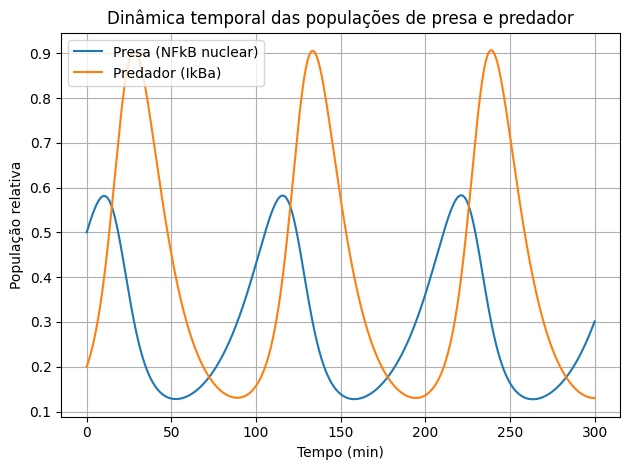

In [ ]:
plt.plot(
    tempo_lv,
    XY[:, 0],
    label="Presa (NFkB nuclear)"
)

plt.plot(
    tempo_lv,
    XY[:, 1],
    label="Predador (IkBa)"
)

plt.title("Dinâmica temporal das populações de presa e predador")
plt.ylabel("População relativa")
plt.xlabel("Tempo (min)")
plt.grid()
plt.legend()
plt.tight_layout()
plt.savefig("População presaxpredador", dpi=300,bbox_inches='tight')
plt.show()

#### Plano de fases das populações de presa e predador

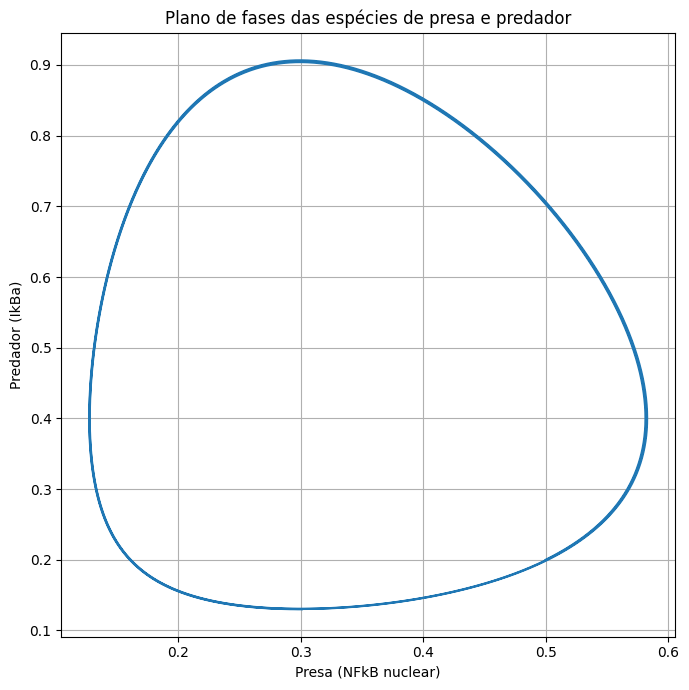

In [ ]:
plt.figure(figsize=(7, 7))

plt.plot(
    XY[:, 0],
    XY[:, 1]
)

plt.xlabel("Presa (NFkB nuclear)")
plt.ylabel("Predador (IkBa)")
plt.title("Plano de fases das espécies de presa e predador")
plt.grid()
plt.tight_layout()
plt.savefig("Plano de fases", dpi=300,bbox_inches='tight')
plt.show()

### Avaliação do modelo BDF

In [ ]:
# função adequada para aplicação no método BDF
def sistema_bdf(t, x):
    
    return sistema(t, x, psi)

In [ ]:
solver = BDF(
    fun=sistema_bdf,
    t0=ti,
    y0=x0,
    t_bound=tf,
    rtol=1e-8,
    atol=1e-10
)

# listas para armazenar as informações do integrador

tempos_bdf = []
ordens_bdf = []
passos_bdf = []
estados_bdf = []

while solver.status == "running":

    solver.step()

    tempos_bdf.append(solver.t)
    
    ordens_bdf.append(solver.order)
    
    passos_bdf.append(solver.step_size)
    
    estados_bdf.append(solver.y.copy())


tempos_bdf = np.array(tempos_bdf)

ordens_bdf = np.array(ordens_bdf)

passos_bdf = np.array(passos_bdf)

estados_bdf = np.array(estados_bdf)

print(
    "Ordens utilizadas:",
    np.unique(ordens_bdf)
)

Ordens utilizadas: [1 2 3 4 5]


In [ ]:
# frequencia da utilização de cada ordem
valores, contagens = np.unique(
    ordens_bdf,
    return_counts=True
)

total_passos = len(ordens_bdf)

tabela_ordens = pd.DataFrame({
    
    "Ordem BDF": valores,
    
    "Número de passos": contagens,
    
    "Porcentagem (%)":
        100 * contagens / total_passos
})

tabela_ordens

,Ordem BDF,Número de passos,Porcentagem (%)
0,1,5,6.25
1,2,8,10.00
2,3,4,5.00
3,4,15,18.75
4,5,48,60.00


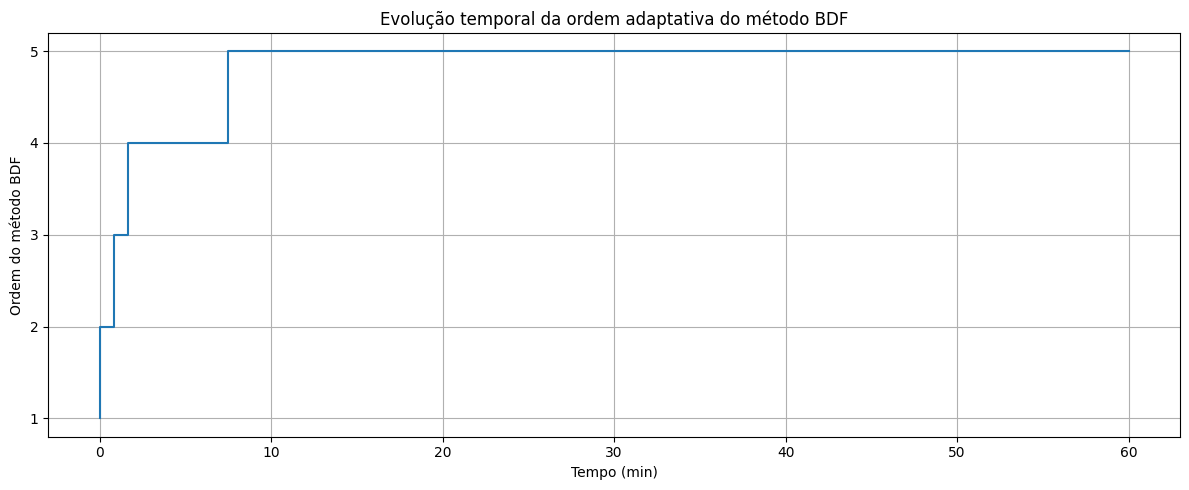

In [ ]:
plt.figure(figsize=(12, 5))

plt.step(
    tempos_bdf,
    ordens_bdf,
    where="post"
)

plt.xlabel("Tempo (min)")

plt.ylabel("Ordem do método BDF")

plt.yticks([1, 2, 3, 4, 5])

plt.title(
    "Evolução temporal da ordem adaptativa do método BDF"
)

plt.grid(True)

plt.tight_layout()

plt.show()

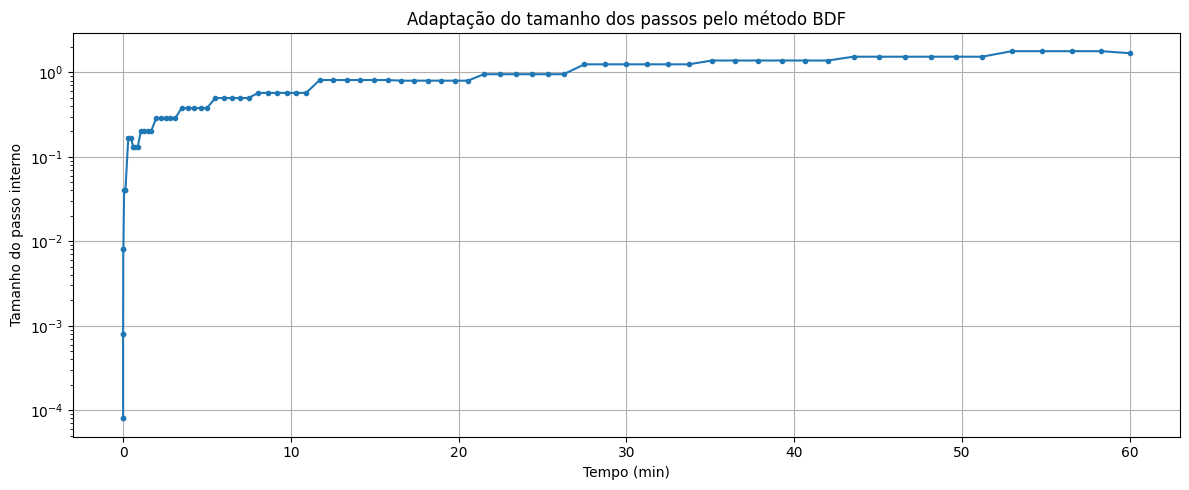

In [ ]:
plt.figure(figsize=(12, 5))

plt.plot(
    tempos_bdf,
    passos_bdf,
    marker="."
)

plt.xlabel("Tempo (min)")

plt.ylabel("Tamanho do passo interno")

plt.title(
    "Adaptação do tamanho dos passos pelo método BDF"
)

plt.yscale("log")

plt.grid(True)

plt.tight_layout()

plt.show()

## Conclusão

O notebook apresentado implementa computacionalmente o modelo da via de sinalização do NFkB, composto por 52 equações diferenciais ordinárias (EDOs), 101 reações bioquímicas e 133 parâmetros cinéticos, descritos no material utilizado como referência. A metodologia utilizada permitiu reproduzir a dinâmica de evolução temporal das espécies químicas relacionadas à resposta imune primária, utilizando para tal a obtenção das condições iniciais por meio do alcance do estado estacionário do sistema por meio do método BDF (Fórmula de Dferenciação Reversa). Em seguida, a solução do sistema de equações apresentado foi aproximada com o uso do método numérico de Euler, sendo posteriormente comparados ambos os métodos e sua previsão para a dinâmica temporal das espécies químicas.

Por fim, implementou-se o modelo de crescimento malthusiano e o modelo de interação Lotka-Voltera, modelos matemáticos simplificados que possibilitam a construção de aproximações para visualizar qualitativamente a dinâmica temporal e de interação entre as espécies químicas que compõem a via de sinalização do NFkB. Para ambos, foram produzidos gráficos que permitem a visualização dos processos descritos.


Os resultados obtidos evidenciam que a dinâmica do NFkB depende fortemente da interação entre múltiplos fatores, desde proteínas reguladoras, receptores de membrana, adaptadores intracelulares, a mecanismos de retroalimentação negativa. Desse modo, a construção efetivada pelo notebook permite a compreensão da influência de processos individuais sobre a dinâmica global da via de ativação do NFkB, modelada através de modelos matemáticos simplificados e cuja solução aproximada se deu com uso do método de Euler.

## Referências

[1] Guo, X., Adelaja, A., Singh, A. et al. Modeling heterogeneous signaling dynamics of macrophages reveals principles of information transmission in stimulus responses. Nat Commun 16, 5986 (2025). https://doi.org/10.1038/s41467-025-60901-3

[2] ADELAJA, Adewunmi et al. Six distinct NFκB signaling codons convey discrete information to distinguish stimuli and enable appropriate macrophage responses. Immunity, v. 54, n. 5, p. 916- 930.e7, 2021.